# ИДЗ №1: Эмпирический и теоретический анализ алгоритмов сортировки

Студент: [Ерёмин Денис Вадимович]  
Группа: [505]  
Дата: 07.11.2026  
Вариант: 
1. Сортировка выбором (Selection Sort) — O(N^2)
2. Глупая сортировка (Stupid Sort) — O(N^3) worst case
3. Быстрая сортировка Хоара (QuickSort Hoare) — O(N \log N)

---

## Цель работы
На практике зафиксировать разницу между O(N^2), O(N^3) и O(N \log N) алгоритмами, 
провести честный бенчмаркинг на 5 типах распределений и подтвердить теоретическую 
асимптотику через Log-Log графики и МНК-аппроксимацию.

In [24]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings('ignore')

# Научный стиль графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [25]:
def selection_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Сортировка выбором.
    """
    cmp, swp = 0, 0 
    '''число сравненией и замен'''
    n = len(arr)
    for i in range(n):
        min_idx = i
        for j in range(i + 1, n):
            cmp += 1
            if arr[j] < arr[min_idx]:
                min_idx = j
        if min_idx != i:
            arr[i], arr[min_idx] = arr[min_idx], arr[i]
            swp += 1
    return arr, cmp, swp
    
def stupid_sort(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Глупая сортировка. При нарушении порядка меняет элементы местами 
    и возвращается в начало массива.
    """
    cmp, swp = 0, 0
    n = len(arr)
    i = 0
    while i < n - 1:
        cmp += 1
        if arr[i] > arr[i + 1]:
            arr[i], arr[i + 1] = arr[i + 1], arr[i]
            swp += 1
            i = 0  # Возврат в начало
        else:
            i += 1
    return arr, cmp, swp

def quicksort_hoare(arr: list[int | float]) -> tuple[list[int | float], int, int]:
    """
    Быстрая сортировка с разбиением Хоара.
    
    """
    counters = [0, 0] 
    '''сравнения и перестановки'''
    
    def _sort(low: int, high: int):
        if low >= high:
            return
        
        pivot = arr[(low + high) // 2]
        i, j = low, high
        
        while True:
            while i <= high and arr[i] < pivot:
                counters[0] += 1
                i += 1
            counters[0] += 1
            
            while j >= low and arr[j] > pivot:
                counters[0] += 1
                j -= 1
            counters[0] += 1
            
            if i <= j:
                arr[i], arr[j] = arr[j], arr[i]
                counters[1] += 1
                i += 1
                j -= 1
            else:
                break
                
        _sort(low, j)
        _sort(i, high)

    if len(arr) > 0:
        _sort(0, len(arr) - 1)
    return arr, counters[0], counters[1]

## 2. Генерация данных и методология бенчмаркинга

Тестирование на 5 типах распределений:
1. `random` — равномерное случайное
2. `sorted` — уже отсортированный
3. `reversed` — обратно отсортированный
4. `nearly_sorted` — 5% случайных перестановок (проверка адаптивности)
5. `duplicates` — всего 5 уникальных значений

Для каждого типа и размера N  выполняется 5 повторов на разных сидах, 
фиксируются среднее mu и стандартное отклонение sigma.

In [26]:
def generate_data(n: int, dist_type: str) -> list[int]:
    
    if dist_type == 'random':
        return np.random.randint(0, 10**9, n).tolist()
    elif dist_type == 'sorted':
        return np.arange(n).tolist()
    elif dist_type == 'reversed':
        return np.arange(n)[::-1].tolist()
    elif dist_type == 'nearly_sorted':
        arr = np.arange(n).tolist()
        swaps = int(n * 0.05)
        for _ in range(swaps):
            i, j = np.random.randint(0, n, 2)
            arr[i], arr[j] = arr[j], arr[i]
        return arr
    elif dist_type == 'duplicates':
        return np.random.choice([1, 2, 3, 4, 5], n).tolist()


In [27]:
def benchmark(sort_func, sizes, distributions, repeats=5):
    """
    Бенчмаркинг алгоритмов сортировки.
    """
    
    results = {
        dist: {
            size: {'times': [], 'cmps': [], 'swps': []} 
            for size in sizes
        } 
        for dist in distributions
    }
    '''Структура ответа в виде тройного dictinary'''
    
    for dist in distributions:
        for n in sizes:
            for _ in range(repeats):
                data = generate_data(n, dist)
                data_copy = data.copy()  

                 
                t_start = time.perf_counter()
                _, cmp, swp = sort_func(data_copy)
                t_end = time.perf_counter()
                '''Замер времени'''
                
                
                results[dist][n]['times'].append((t_end - t_start) * 1000)
                results[dist][n]['cmps'].append(cmp)
                results[dist][n]['swps'].append(swp)
                '''Фиксация результатов'''
                
    return results


In [28]:
sizes_o_n2 = [100, 200, 300, 400, 500] # Для Stupid Sort ограничим 500
sizes_o_nlogn = [1000, 5000, 10000, 50000, 100000, 300000, 500000, 1000000]

distributions = ['random', 'sorted', 'reversed', 'nearly_sorted', 'duplicates']

print("Запуск бенчмарков... (Это может занять несколько минут для Stupid Sort)")
res_selection = benchmark(selection_sort, sizes_o_n2, distributions)
res_stupid = benchmark(stupid_sort, sizes_o_n2, distributions)
res_quick = benchmark(quicksort_hoare, sizes_o_nlogn, distributions)
print("Готово!")

Запуск бенчмарков... (Это может занять несколько минут для Stupid Sort)
Готово!


## 3. Научная визуализация

Построим графики в двух масштабах:
Линейный — для наглядной демонстрации качественной разницы между алгоритмами
Log-Log — для количественной верификации теоретической степени сложности

Наклон прямой на Log-Log графике численно равен степени k в формуле T(N) = c * N^k.

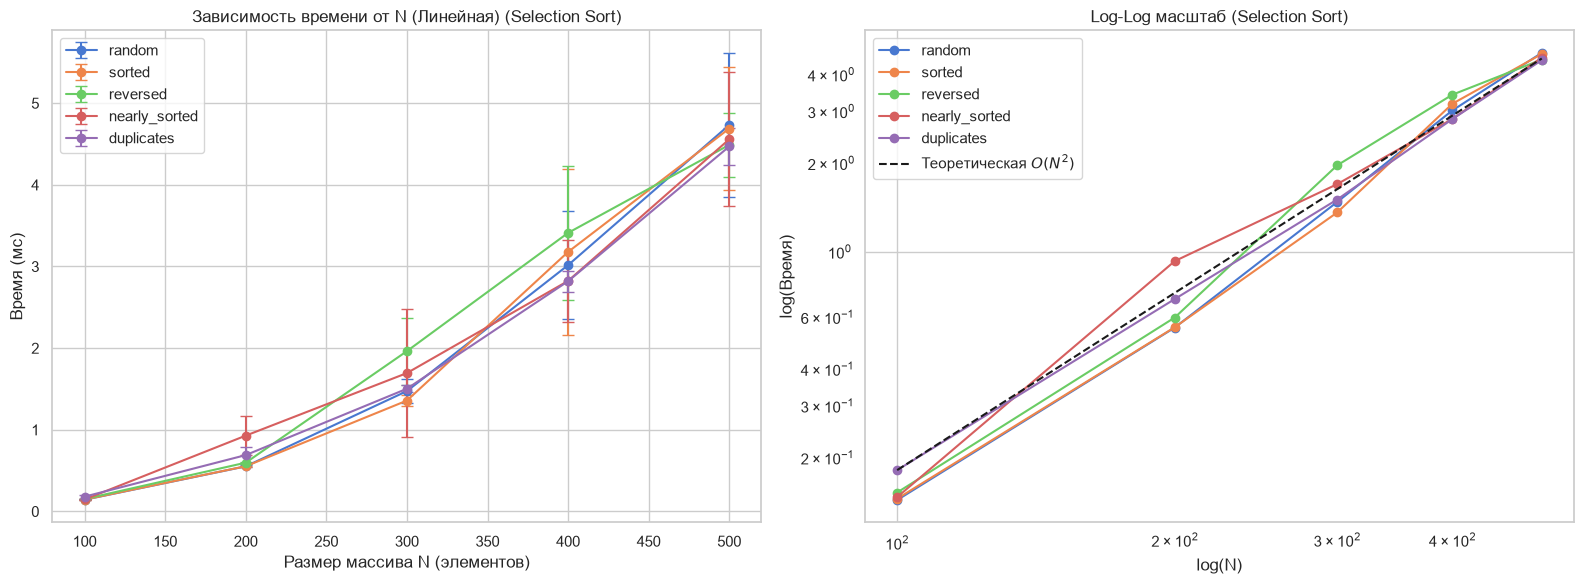

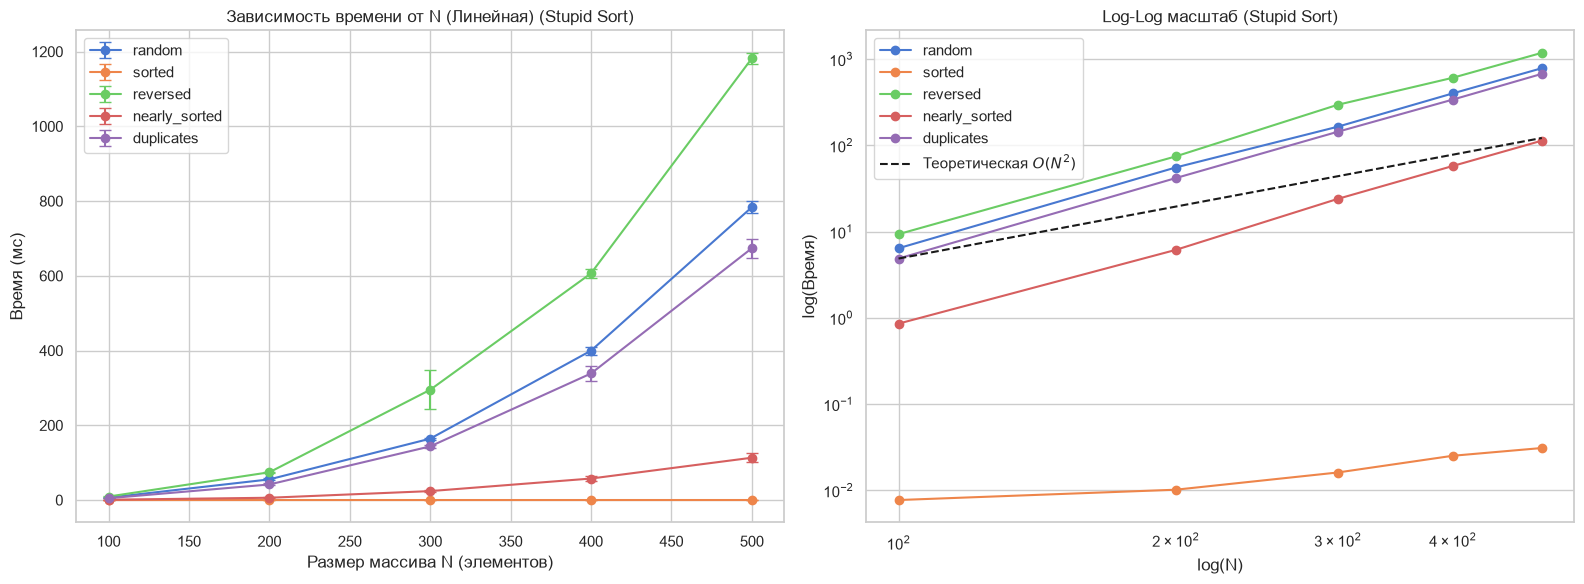

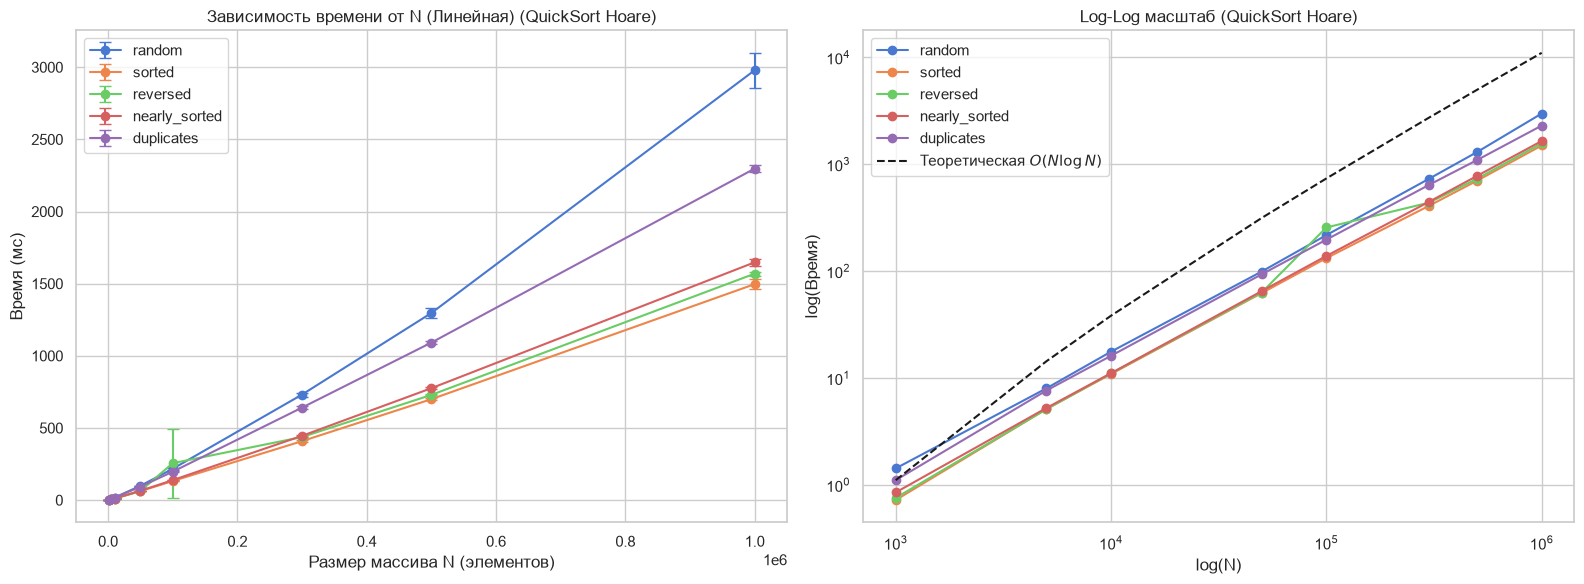

In [29]:
def plot_results(results, sizes, title_suffix, func_type='O(N^2)'):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    
    for dist in distributions:
        means = [np.mean(results[dist][n]['times']) for n in sizes]
        stds = [np.std(results[dist][n]['times']) for n in sizes]
        axes[0].errorbar(sizes, means, yerr=stds, marker='o', label=dist, capsize=4)
    axes[0].set_title(f'Зависимость времени от N (Линейная) {title_suffix}')
    axes[0].set_xlabel('Размер массива N (элементов)')
    axes[0].set_ylabel('Время (мс)')
    axes[0].legend()
    
    # 2. Log-Log масштаб
    for dist in distributions:
        means = [np.mean(results[dist][n]['times']) for n in sizes]
        axes[1].loglog(sizes, means, marker='o', label=dist)
    if func_type == 'O(N^2)':
        axes[1].loglog(sizes, [means[0] * (n/sizes[0])**2 for n in sizes], 
                       'k--', label='Теоретическая $O(N^2)$')
    else:
        axes[1].loglog(sizes, [means[0] * (n/sizes[0]) * np.log2(n/sizes[0] + 1) for n in sizes], 
                       'k--', label='Теоретическая $O(N \log N)$')
                       
    axes[1].set_title(f'Log-Log масштаб {title_suffix}')
    axes[1].set_xlabel('log(N)')
    axes[1].set_ylabel('log(Время)')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

plot_results(res_selection, sizes_o_n2, '(Selection Sort)', 'O(N^2)')
plot_results(res_stupid, sizes_o_n2, '(Stupid Sort)', 'O(N^2)')
plot_results(res_quick, sizes_o_nlogn, '(QuickSort Hoare)', 'O(N log N)')

 Selection Sort $c \cdot N^2$
   Коэффициент c = 1.861e-05 ± 4.717e-07


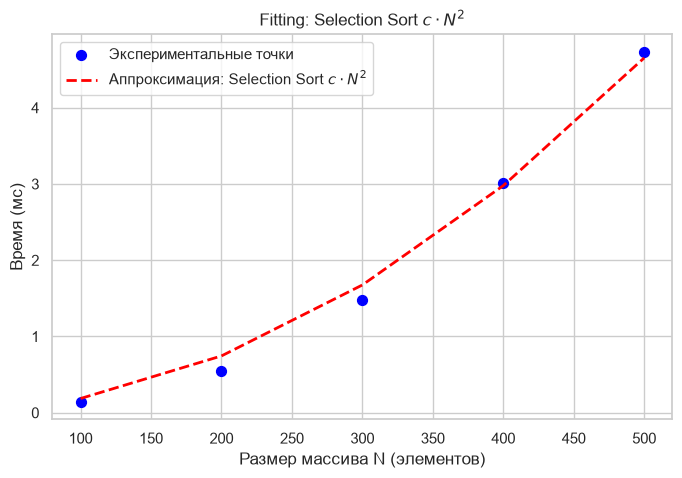

 Stupid Sort $c \cdot N^3$
   Коэффициент c = 6.260e-06 ± 2.522e-08


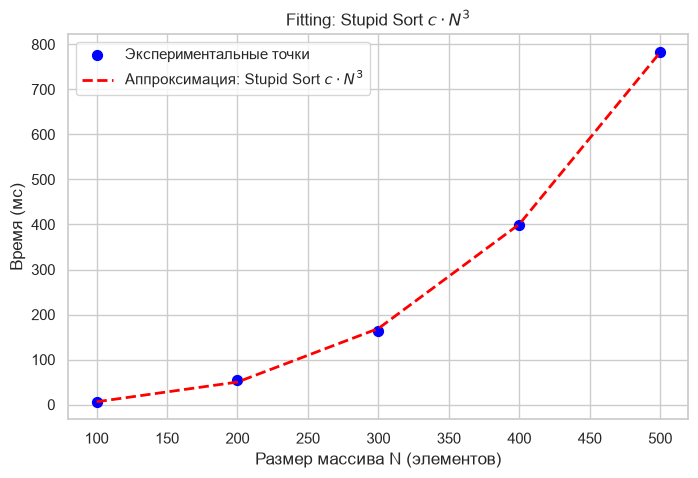

 QuickSort $c \cdot N \log_2 N$
   Коэффициент c = 1.463e-04 ± 2.172e-06


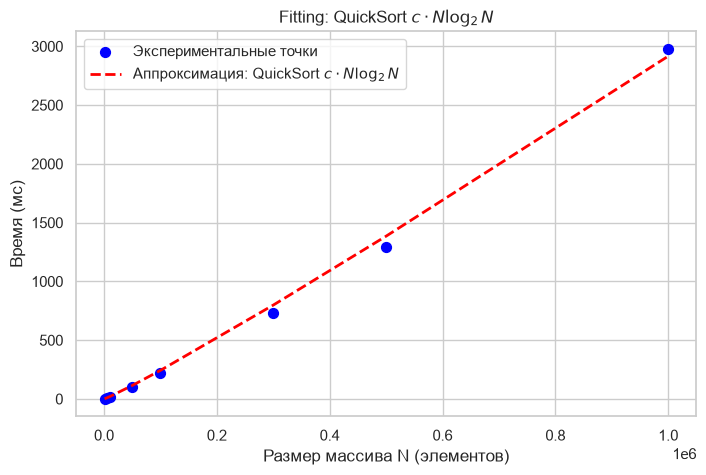

In [30]:
def fit_curve(results, sizes, func, label):
    times = [np.mean(results['random'][n]['times']) for n in sizes]
    
    
    x_data = np.array(sizes)
    y_data = np.array(times)
    
    popt, pcov = curve_fit(func, x_data, y_data, p0=[1e-10])
    perr = np.sqrt(np.diag(pcov))
    
    print(f" {label}")
    print(f"   Коэффициент c = {popt[0]:.3e} ± {perr[0]:.3e}")
    
    plt.figure(figsize=(8, 5))
    plt.scatter(x_data, y_data, label='Экспериментальные точки', color='blue', s=50)
    plt.plot(x_data, func(x_data, *popt), '--', 
             label=f'Аппроксимация: {label}', color='red', linewidth=2)
    plt.title(f'Fitting: {label}')
    plt.xlabel('Размер массива N (элементов)')
    plt.ylabel('Время (мс)')
    plt.legend()
    plt.grid(True)
    plt.show()
fit_curve(res_selection, sizes_o_n2, lambda x, c: c * x**2, 
          'Selection Sort $c \\cdot N^2$')
fit_curve(res_stupid, sizes_o_n2, lambda x, c: c * x**3, 
          'Stupid Sort $c \\cdot N^3$')
fit_curve(res_quick, sizes_o_nlogn, lambda x, c: c * x * np.log2(x), 
          'QuickSort $c \\cdot N \\log_2 N$')




In [31]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

def results_to_summary_df(results, sizes, distributions, algo_name):
    """
    Преобразует словарь результатов в pandas DataFrame 
    с колонками: distribution, N, mean_time_ms, std_time_ms, 
    mean_cmp, mean_swp, mean_mem_mb.
    """
    rows = []
    for dist in distributions:
        for n in sizes:
            times = results[dist][n]['times']
            cmps = results[dist][n]['cmps']
            swps = results[dist][n]['swps']
            
            rows.append({
                'algorithm': algo_name,
                'distribution': dist,
                'N': n,
                'time_mean_ms': np.mean(times),
                'time_std_ms': np.std(times),
                'cmp_mean': np.mean(cmps),
                'swp_mean': np.mean(swps),
            })
    
    return pd.DataFrame(rows)


# Создаём сводные таблицы для всех трёх алгоритмов
df_selection = results_to_summary_df(res_selection, sizes_o_n2, distributions, 'Selection Sort')
df_stupid = results_to_summary_df(res_stupid, sizes_o_n2, distributions, 'Stupid Sort')
df_quick = results_to_summary_df(res_quick, sizes_o_nlogn, distributions, 'QuickSort Hoare')

# Объединяем в одну таблицу
df_summary = pd.concat([df_selection, df_stupid, df_quick], ignore_index=True)

# Форматируем 
df_summary['time (μ ± σ), мс'] = df_summary.apply(
    lambda r: f"{r['time_mean_ms']:.3f} ± {r['time_std_ms']:.3f}", axis=1
)
df_summary['cmp (среднее)'] = df_summary['cmp_mean'].apply(lambda x: f"{x:,.0f}".replace(',', ' '))
df_summary['swp (среднее)'] = df_summary['swp_mean'].apply(lambda x: f"{x:,.0f}".replace(',', ' '))


# Финальная таблица для отображения
df_display = df_summary[['algorithm', 'distribution', 'N', 
                         'time (μ ± σ), мс', 'cmp (среднее)']]

display(df_display)

,algorithm,distribution,N,"time (μ ± σ), мс",cmp (среднее)
0,Selection Sort,random,100,0.143 ± 0.003,4 950
1,Selection Sort,random,200,0.552 ± 0.012,19 900
2,Selection Sort,random,300,1.474 ± 0.149,44 850
3,Selection Sort,random,400,3.016 ± 0.662,79 800
4,Selection Sort,random,500,4.733 ± 0.884,124 750
5,Selection Sort,sorted,100,0.145 ± 0.004,4 950
6,Selection Sort,sorted,200,0.554 ± 0.003,19 900
7,Selection Sort,sorted,300,1.358 ± 0.068,44 850
8,Selection Sort,sorted,400,3.178 ± 1.017,79 800
9,Selection Sort,sorted,500,4.690 ± 0.750,124 750
